# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name:** Wajood Ali

**Student ID:** 023-24-0006

**Section:** CS AI Sec B

**GitHub:** https://github.com/wajoodali77-maker

**Kaggle:** https://www.kaggle.com/wajoodali

**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment
**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [9]:
# YOUR CODE HERE
import pandas as pd
import re
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [10]:
# Task 1 — load spam.csv, inspect shape/head/class balance
spam = pd.read_csv("spam.csv", encoding="latin-1")

spam = spam.rename(columns={"v1": "label", "v2": "message"})[["label", "message"]]

print("Rows:", len(spam))
print("\nClass balance:")
print(spam["label"].value_counts())

display(spam.head())

Rows: 5572

Class balance:
label
ham     4825
spam     747
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [11]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance
tweets = pd.read_csv("Tweets.csv")
print("Original rows:", len(tweets))
print("Each row represents one airline-related tweet.")
print("\nOriginal class balance:")
tweet_balance_original = tweets["airline_sentiment"].value_counts().rename_axis("class").to_frame("count")
tweet_balance_original["percentage"] = tweets["airline_sentiment"].value_counts(normalize=True).mul(100).round(2)
display(tweet_balance_original)

tweets = tweets[tweets["airline_sentiment"].isin(["positive", "negative"])].copy()
print("Rows after dropping neutral:", len(tweets))
tweet_balance = tweets["airline_sentiment"].value_counts().rename_axis("class").to_frame("count")
tweet_balance["percentage"] = tweets["airline_sentiment"].value_counts(normalize=True).mul(100).round(2)
display(tweet_balance)

Original rows: 14640
Each row represents one airline-related tweet.

Original class balance:


,count,percentage
class,,
negative,9178,62.69
neutral,3099,21.17
positive,2363,16.14


Rows after dropping neutral: 11541


,count,percentage
class,,
negative,9178,79.53
positive,2363,20.47


**Answer 2 (Task A — spam):**
The practical problem is to automatically classify SMS messages as spam or ham(legitimate). It is binary classification because every message belongs to one of two target classes: ham(0) or spam(1)

**Answer 2 (Task B — sentiment):**
The practical problem is to classify airline-related tweets as **negative** or **positive** sentiment. It is binary classification after removing neutral tweets because each remaining tweet belongs to one of two target classes: negative (0) or positive (1).

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [12]:
# Task 3 — clean text
spam["message"] = spam["message"].fillna("").astype(str).str.lower()
spam["label_bin"] = spam["label"].map({"ham": 0, "spam": 1})
spam.head()

,label,message,label_bin
0,ham,"go until jurong point, crazy.. available only ...",0
1,ham,ok lar... joking wif u oni...,0
2,spam,free entry in 2 a wkly comp to win fa cup fina...,1
3,ham,u dun say so early hor... u c already then say...,0
4,ham,"nah i don't think he goes to usf, he lives aro...",0


In [13]:
# Task 4 — encode labels, split, fit vectorizer on train only, transform both sets
X_train, X_test, y_train, y_test = train_test_split(
    spam["message"], spam["label_bin"], test_size=0.20, random_state=42, stratify=spam["label_bin"]
)

vectorizer = CountVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("Training samples:", X_train_vec.shape[0])
print("Test samples:", X_test_vec.shape[0])
print("Vocabulary size:", len(vectorizer.get_feature_names_out()))
print("Train matrix shape:", X_train_vec.shape)
print("Test matrix shape:", X_test_vec.shape)

Training samples: 4457
Test samples: 1115
Vocabulary size: 7701
Train matrix shape: (4457, 7701)
Test matrix shape: (1115, 7701)


**Answer 4 (why fit on training data only):**
The vectorizer must be fitted only on the training data to prevent information from the test set leaking into the model. The test set should represent unseen data, so its vocabulary statistics must not influence training.

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

Accuracy:  0.9839
Precision: 0.9645
Recall:    0.9128
F1-score:  0.9379


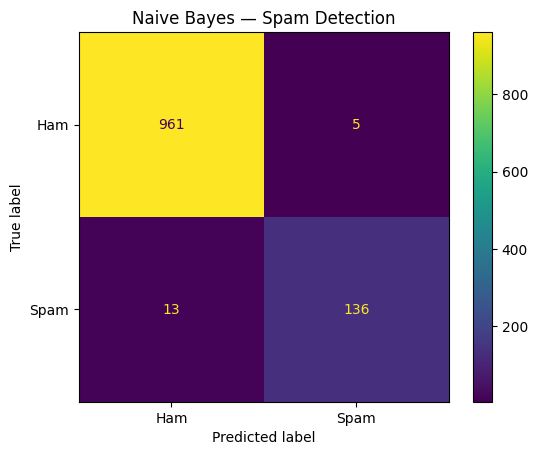

In [14]:
# Task 5 — train MultinomialNB, compute metrics, plot confusion matrix
nb_spam = MultinomialNB()
nb_spam.fit(X_train_vec, y_train)
spam_pred = nb_spam.predict(X_test_vec)

spam_accuracy = accuracy_score(y_test, spam_pred)
spam_precision = precision_score(y_test, spam_pred)
spam_recall = recall_score(y_test, spam_pred)
spam_f1 = f1_score(y_test, spam_pred)
spam_cm = confusion_matrix(y_test, spam_pred)

print(f"Accuracy:  {spam_accuracy:.4f}")
print(f"Precision: {spam_precision:.4f}")
print(f"Recall:    {spam_recall:.4f}")
print(f"F1-score:  {spam_f1:.4f}")

ConfusionMatrixDisplay(confusion_matrix=spam_cm, display_labels=["Ham", "Spam"]).plot()
plt.title("Naive Bayes — Spam Detection")
plt.show()

**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.9839 |
| Precision | 0.9645 |
| Recall | 0.9128 |
| F1-score | 0.9379 |

**Answer 6:**
false negatives are more numerous than false positives (13 vs. 5), so a spam message is more likely to get through than a legitimate message is to be blocked. Therefore, I would prioritize **recall** when tuning the model, while still monitoring precision to avoid incorrectly flagging legitimate messages.

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [15]:
# Task 7 — extract top spam words and top ham words from feature_log_prob_
features = vectorizer.get_feature_names_out()
log_prob_diff = nb_spam.feature_log_prob_[1] - nb_spam.feature_log_prob_[0]

top_spam = features[np.argsort(log_prob_diff)[-15:][::-1]]
top_ham = features[np.argsort(log_prob_diff)[:15]]

print("15 words most strongly associated with spam:")
print(", ".join(top_spam))
print("\n15 words most strongly associated with ham:")
print(", ".join(top_ham))

15 words most strongly associated with spam:
claim, prize, 150p, tone, 18, cs, guaranteed, 500, 1000, uk, 150ppm, awarded, www, collection, rate

15 words most strongly associated with ham:
gt, lt, he, lor, da, she, later, ì_, ll, doing, say, really, ask, home, anything


**Answer 7:**
The 15 words most strongly associated with spam are: **claim, prize, 150p, tone, 18, cs, guaranteed, 500, 1000, uk, 150ppm, awarded, www, collection, rate**.

The 15 words most strongly associated with ham are: **gt, lt, he, da, lor, she, later, ì_, ll, doing, say, really, ask, home, amp**.

Yes, many spam words match the intuition that promotional, prize, money, and payment-related language is common in spam. Some ham words are less meaningful individually because short conversational words and SMS artifacts can be predictive.

In [16]:
# Task 8 — test your own messages
my_messages = [
    "Congratulations! You have won a £1000 cash prize. Call now to claim.",
    "Hey, are we still meeting for lunch today?",
    "URGENT! You have been selected for a guaranteed free reward."
]

my_vec = vectorizer.transform([m.lower() for m in my_messages])
my_pred = nb_spam.predict(my_vec)

for msg, label in zip(my_messages, my_pred):
    print(f"{label} -> {'spam' if label == 1 else 'ham'}: {msg}")

1 -> spam: Congratulations! You have won a £1000 cash prize. Call now to claim.
0 -> ham: Hey, are we still meeting for lunch today?
1 -> spam: URGENT! You have been selected for a guaranteed free reward.


**Answer 8:**
The three test messages were classified as:

- “Congratulations! You have won a £1000 cash prize. Call now to claim.” → **Spam**
- “Hey, are we still meeting for lunch today?” → **Ham**
- “URGENT! You have been selected for a guaranteed free reward.” → **Spam**

The predictions match the expected labels because the first and third messages contain strong promotional/spam language, while the second is a normal conversational message.

---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
https://www.kaggle.com/code/wajoodali/task-a-sms-spam-collection

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [19]:
# Task 11 — clean and vectorize the sentiment data (your own approach)
def clean_tweet(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)  # remove URLs
    text = re.sub(r"@\w+", " ", text)                # remove @mentions
    text = re.sub(r"#", "", text)                     # keep hashtag word, remove only '#'
    text = re.sub(r"[^a-z0-9\s]", " ", text)         # remove punctuation/symbols
    text = re.sub(r"\s+", " ", text).strip()
    return text

tweets["clean_text"] = tweets["text"].fillna("").map(clean_tweet)
tweets["label_bin"] = tweets["airline_sentiment"].map({"negative": 0, "positive": 1})

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    tweets["clean_text"], tweets["label_bin"], test_size=0.20, random_state=42, stratify=tweets["label_bin"]
)

tweet_vectorizer = CountVectorizer()
X_train_t_vec = tweet_vectorizer.fit_transform(X_train_t)
X_test_t_vec = tweet_vectorizer.transform(X_test_t)

print("Training samples:", X_train_t_vec.shape[0])
print("Test samples:", X_test_t_vec.shape[0])
print("Vocabulary size:", len(tweet_vectorizer.get_feature_names_out()))

Training samples: 9232
Test samples: 2309
Vocabulary size: 10081


**Answer 12:**
I removed URLs and @mention beacause they are often noisy identifier rather than useful sentiment feature. I kept hashtag words by removing only the '#' symbol, and removed punctuation while perserving the main content.

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

Accuracy:  0.9039
Precision: 0.9115
Recall:    0.5877
F1-score:  0.7147


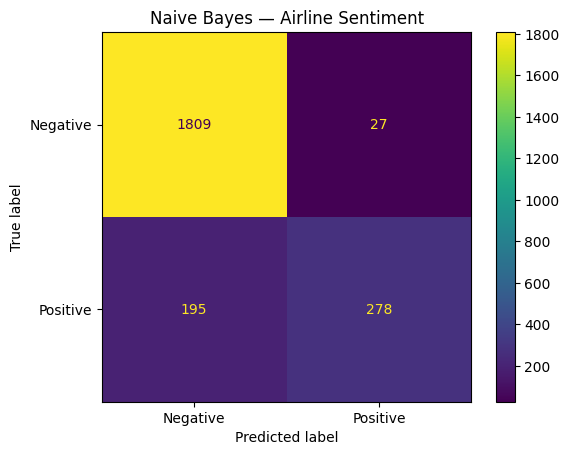

In [18]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix
nb_sentiment = MultinomialNB()
nb_sentiment.fit(X_train_t_vec, y_train_t)
sentiment_pred = nb_sentiment.predict(X_test_t_vec)

sent_accuracy = accuracy_score(y_test_t, sentiment_pred)
sent_precision = precision_score(y_test_t, sentiment_pred)
sent_recall = recall_score(y_test_t, sentiment_pred)
sent_f1 = f1_score(y_test_t, sentiment_pred)
sent_cm = confusion_matrix(y_test_t, sentiment_pred)

print(f"Accuracy:  {sent_accuracy:.4f}")
print(f"Precision: {sent_precision:.4f}")
print(f"Recall:    {sent_recall:.4f}")
print(f"F1-score:  {sent_f1:.4f}")

ConfusionMatrixDisplay(confusion_matrix=sent_cm, display_labels=["Negative", "Positive"]).plot()
plt.title("Naive Bayes — Airline Sentiment")
plt.show()

**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---:|
| Accuracy | 0.9039 |
| Precision | 0.9115 |
| Recall | 0.5877 |
| F1-score | 0.7147 |

**Answer 14:**
Naive Bayes achieved higher accuracy and F1 on the spam task than on the sentiment task. Sentiment is harder because words can depend strongly on context, negation, and combinations with other words. The naive independence assumption treats features as conditionally independent given the class, which is less realistic for tweets where word relationships often carry meaning. Spam SMS messages contain more direct keyword patterns, so the assumption is more useful there.

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
https://www.kaggle.com/code/wajoodali/task-b-twitter-us-sentiment

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---:|---:|
| Accuracy | 0.9839 | 0.9039 |
| Precision | 0.9645 | 0.9115 |
| Recall | 0.9128 | 0.5877 |
| F1-score | 0.9379 | 0.7147 |

In [ ]:
# Task 18 — train Logistic Regression on Task A's vectorized features
lr_spam = LogisticRegression(max_iter=1000)
lr_spam.fit(X_train_vec, y_train)
lr_pred = lr_spam.predict(X_test_vec)

lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)

print(f"Accuracy:  {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall:    {lr_recall:.4f}")
print(f"F1-score:  {lr_f1:.4f}")

**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---:|---:|
| Accuracy | 0.9839 | 0.9812 |
| Precision | 0.9645 | 0.9923 |
| Recall | 0.9128 | 0.8658 |
| F1-score | 0.9379 | 0.9247 |

**Answer 18 (which wins, and does it match expectations):**

Naive Bayes has higher accuracy, recall, and F1-score, while Logistic Regression has higher precision. Based on the four reported metrics, Naive Bayes performs better overall on this particular test split. This is plausible because Multinomial Naive Bayes works well with word-count features and relatively direct spam-related word patterns.

---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
Naive Bayes performed better on the spam task than on the sentiment task, especially in recall and F1-score. The spam dataset contains strong word patterns such as prize, claim, guaranteed, and money-related terms. Some of the most predictive ham words were short conversational words and SMS artifacts, which was less intuitive than the spam vocabulary. On Task A, Naive Bayes had higher accuracy, recall, and F1-score than Logistic Regression, while Logistic Regression had higher precision. The results show that the independence assumption can work well when individual words are strong class indicators. For tweets, the assumption is more limited because sentiment often depends on word combinations and context. Overall, the experiments show that the same text-classification pipeline can transfer to a new dataset, but its performance depends on the language patterns in the task.  

**Answer 20 — Kaggle Notebook Links:**
- Task A: https://www.kaggle.com/code/wajoodali/task-a-sms-spam-collection
- Task B: https://www.kaggle.com/code/wajoodali/task-b-twitter-us-sentiment

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [ ] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [ ] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [ ] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [ ] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [ ] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [ ] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [ ] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [ ] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted